In [11]:
import pandas as pd
from scipy.io import arff
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:

# Ler base arff
dados_arff, metadados = arff.loadarff('dataset_44_spambase.arff')

# Converter para pd

df = pd.DataFrame(dados_arff)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 non-null   

In [6]:

print("\nPrimeiras colunas:")
print(df.columns[:10].tolist())

print("\nResumo das variáveis:")
df.describe().T


Primeiras colunas:
['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d', 'word_freq_our', 'word_freq_over', 'word_freq_remove', 'word_freq_internet', 'word_freq_order', 'word_freq_mail']

Resumo das variáveis:


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.104553,0.305358,0.0,0.000,0.000,0.000,4.540
word_freq_address,4601.0,0.213015,1.290575,0.0,0.000,0.000,0.000,14.280
word_freq_all,4601.0,0.280656,0.504143,0.0,0.000,0.000,0.420,5.100
word_freq_3d,4601.0,0.065425,1.395151,0.0,0.000,0.000,0.000,42.810
word_freq_our,4601.0,0.312223,0.672513,0.0,0.000,0.000,0.380,10.000
word_freq_over,4601.0,0.095901,0.273824,0.0,0.000,0.000,0.000,5.880
word_freq_remove,4601.0,0.114208,0.391441,0.0,0.000,0.000,0.000,7.270
word_freq_internet,4601.0,0.105295,0.401071,0.0,0.000,0.000,0.000,11.110
word_freq_order,4601.0,0.090067,0.278616,0.0,0.000,0.000,0.000,5.260
word_freq_mail,4601.0,0.239413,0.644755,0.0,0.000,0.000,0.160,18.180


In [8]:

# Agrupamento dos atributos conforme suas definições
word_cols = [
    col for col in df.columns
    if col.startswith("word_freq_")
]

char_cols = [
    col for col in df.columns
    if col.startswith("char_freq_")
]

capital_cols = [
    col for col in df.columns
    if col.startswith("capital_run_length_")
]

print(f"Frequências de palavras: {len(word_cols)}")
print(f"Frequências de caracteres: {len(char_cols)}")
print(f"Medidas de letras maiúsculas: {len(capital_cols)}")

print("\nResumo das escalas por grupo:")
for nome, colunas in {
    "Palavras": word_cols,
    "Caracteres": char_cols,
    "Letras maiúsculas": capital_cols
}.items():
    print(f"\n{nome}")
    display(df[colunas].describe().T[["mean", "std", "min", "max"]].round(3))


Frequências de palavras: 48
Frequências de caracteres: 6
Medidas de letras maiúsculas: 3

Resumo das escalas por grupo:

Palavras


,mean,std,min,max
word_freq_make,0.105,0.305,0.0,4.54
word_freq_address,0.213,1.291,0.0,14.28
word_freq_all,0.281,0.504,0.0,5.10
word_freq_3d,0.065,1.395,0.0,42.81
word_freq_our,0.312,0.673,0.0,10.00
word_freq_over,0.096,0.274,0.0,5.88
word_freq_remove,0.114,0.391,0.0,7.27
word_freq_internet,0.105,0.401,0.0,11.11
word_freq_order,0.090,0.279,0.0,5.26
word_freq_mail,0.239,0.645,0.0,18.18



Caracteres


,mean,std,min,max
char_freq_%3B,0.039,0.243,0.0,4.385
char_freq_%28,0.139,0.270,0.0,9.752
char_freq_%5B,0.017,0.109,0.0,4.081
char_freq_%21,0.269,0.816,0.0,32.478
char_freq_%24,0.076,0.246,0.0,6.003
char_freq_%23,0.044,0.429,0.0,19.829



Letras maiúsculas


,mean,std,min,max
capital_run_length_average,5.192,31.729,1.0,1102.5
capital_run_length_longest,52.173,194.891,1.0,9989.0
capital_run_length_total,283.289,606.348,1.0,15841.0


In [9]:

# Remoção do índice sequencial, quando presente
if "Unnamed: 0" in df.columns:
    df = df.drop(columns="Unnamed: 0")

# Conversão dos rótulos b'0' e b'1' para inteiros
df["class"] = (
    df["class"]
    .astype(str)
    .str.replace("b'", "", regex=False)
    .str.replace("'", "", regex=False)
    .astype(int)
)

# Separação conceitual entre atributos e variável-alvo
X = df.drop(columns="class")
y = df["class"]

print(f"Observações: {len(df)}")
print(f"Atributos preditores: {X.shape[1]}")
print(f"Valores ausentes: {df.isna().sum().sum()}")
print(f"Linhas duplicadas completas: {df.duplicated().sum()}")
print(f"Linhas duplicadas nos atributos: {X.duplicated().sum()}")


Observações: 4601
Atributos preditores: 57
Valores ausentes: 0
Linhas duplicadas completas: 391
Linhas duplicadas nos atributos: 394


,Quantidade,Percentual (%)
Não spam (0),2788,60.6
Spam (1),1813,39.4


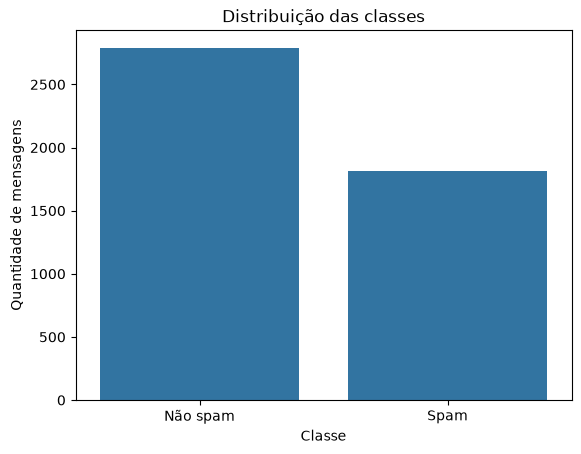

In [12]:

# Frequência absoluta e relativa das classes
distribuicao = pd.DataFrame({
    "Quantidade": y.value_counts().sort_index(),
    "Percentual (%)": (
        y.value_counts(normalize=True).sort_index() * 100
    )
})

distribuicao.index = ["Não spam (0)", "Spam (1)"]

display(distribuicao.round(2))

# Visualização da distribuição
sns.countplot(x=y)
plt.xticks([0, 1], ["Não spam", "Spam"])
plt.xlabel("Classe")
plt.ylabel("Quantidade de mensagens")
plt.title("Distribuição das classes")
plt.show()


In [15]:

# Estatísticas descritivas dos atributos numéricos
estatisticas = X.describe().T

estatisticas["Percentual de zeros (%)"] = (
    X.eq(0).mean() * 100
)

display(
    estatisticas[
        ["mean", "std", "min", "50%", "max", "Percentual de zeros (%)"]
    ].round(3).sort_values("Percentual de zeros (%)", ascending = True)
)


,mean,std,min,50%,max,Percentual de zeros (%)
capital_run_length_total,283.289,606.348,1.0,95.000,15841.000,0.000
capital_run_length_average,5.192,31.729,1.0,2.276,1102.500,0.000
capital_run_length_longest,52.173,194.891,1.0,15.000,9989.000,0.000
word_freq_you,1.662,1.775,0.0,1.310,18.750,29.863
char_freq_%28,0.139,0.270,0.0,0.065,9.752,40.991
word_freq_your,0.810,1.201,0.0,0.220,11.110,47.338
word_freq_will,0.542,0.862,0.0,0.100,9.670,49.468
char_freq_%21,0.269,0.816,0.0,0.000,32.478,50.924
word_freq_all,0.281,0.504,0.0,0.000,5.100,58.965
word_freq_our,0.312,0.673,0.0,0.000,10.000,62.008


In [ ]:

# Atributos com maior desvio-padrão
variabilidade = X.std().sort_values(ascending=False)

display(variabilidade.head(10).to_frame("Desvio-padrão"))

# Atributos com maior proporção de zeros
proporcao_zeros = X.eq(0).mean().sort_values(ascending=False) * 100

display(proporcao_zeros.head(10).to_frame("Zeros (%)").round(2))


,Desvio-padrão
capital_run_length_total,606.347851
capital_run_length_longest,194.891310
capital_run_length_average,31.729449
word_freq_george,3.367292
word_freq_you,1.775481
word_freq_hp,1.671349
word_freq_3d,1.395151
word_freq_address,1.290575
word_freq_your,1.200810
word_freq_font,1.025756


,Zeros (%)
word_freq_3d,98.98
word_freq_table,98.63
word_freq_parts,98.20
word_freq_font,97.46
word_freq_cs,96.78
word_freq_conference,95.59
word_freq_857,95.54
word_freq_415,95.33
word_freq_telnet,93.63
word_freq_project,92.89


In [17]:

# Registros repetidos em todos os atributos, incluindo a classe
duplicados_completos = df.duplicated().sum()

# Grupos de atributos idênticos associados a mais de uma classe
grupos_por_atributos = (
    df.groupby(list(X.columns), dropna=False)["class"]
    .nunique()
)

grupos_conflitantes = grupos_por_atributos[
    grupos_por_atributos > 1
]

print(f"Registros duplicados completos: {duplicados_completos}")
print(
    "Combinações de atributos associadas a classes diferentes:",
    len(grupos_conflitantes)
)


Registros duplicados completos: 391
Combinações de atributos associadas a classes diferentes: 3


,Não spam,Spam,Diferença absoluta
capital_run_length_total,161.471,470.619,309.148
capital_run_length_longest,18.214,104.393,86.179
capital_run_length_average,2.377,9.519,7.142
word_freq_george,1.265,0.002,1.264
word_freq_you,1.270,2.265,0.994
word_freq_your,0.439,1.380,0.942
word_freq_hp,0.895,0.017,0.878
word_freq_free,0.074,0.518,0.445
word_freq_hpl,0.432,0.009,0.423
char_freq_%21,0.110,0.514,0.404


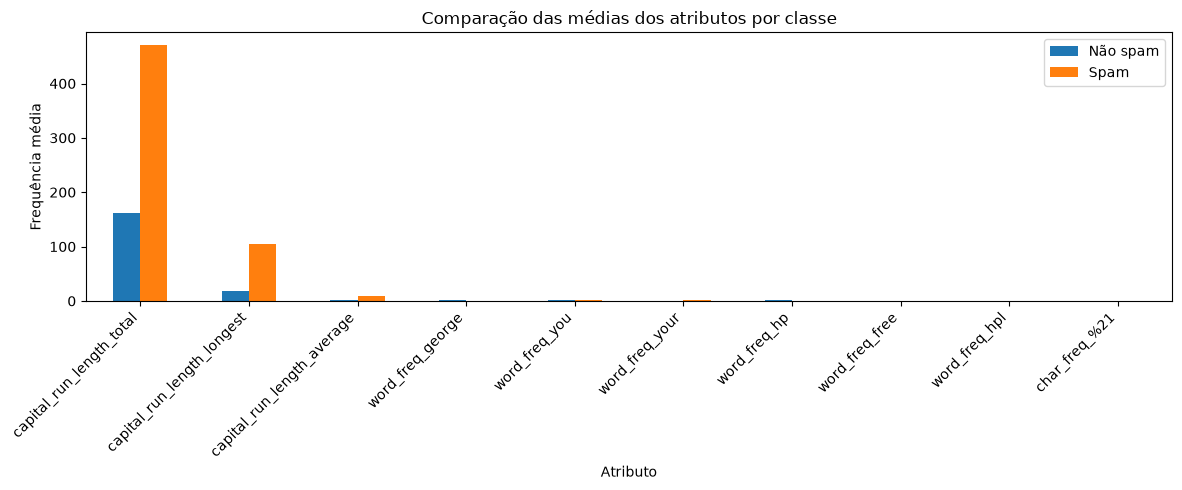

In [18]:

# Comparação das médias dos atributos entre as classes
medias_por_classe = X.groupby(y).mean().T

medias_por_classe.columns = ["Não spam", "Spam"]

medias_por_classe["Diferença absoluta"] = (
    medias_por_classe["Spam"] - medias_por_classe["Não spam"]
).abs()

top_atributos = (
    medias_por_classe
    .sort_values("Diferença absoluta", ascending=False)
    .head(10)
)

display(top_atributos.round(3))

# Visualização dos dez atributos selecionados
atributos_plot = top_atributos.index

medias_por_classe.loc[
    atributos_plot, ["Não spam", "Spam"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.ylabel("Frequência média")
plt.xlabel("Atributo")
plt.title("Comparação das médias dos atributos por classe")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [20]:
from sklearn.model_selection import StratifiedGroupKFold

# Identifica linhas com exatamente a mesma combinação de atributos.
# Linhas com os mesmos atributos ficarão sempre no mesmo grupo.
grupos = pd.MultiIndex.from_frame(X).factorize()[0]

# Aproximadamente 2/3 para treino e 1/3 para teste.
separador = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

indices_treino, indices_teste = next(
    separador.split(X, y, groups=grupos)
)

X_treino = X.iloc[indices_treino]
X_teste = X.iloc[indices_teste]
y_treino = y.iloc[indices_treino]
y_teste = y.iloc[indices_teste]

print(f"Treino: {len(X_treino)} registros")
print(f"Teste: {len(X_teste)} registros")

print("\nProporção das classes:")
print("Treino:")
print(y_treino.value_counts(normalize=True).sort_index().round(3))
print("Teste:")
print(y_teste.value_counts(normalize=True).sort_index().round(3))

# Verifica se alguma combinação de atributos aparece nos dois conjuntos.
grupos_treino = set(grupos[indices_treino])
grupos_teste = set(grupos[indices_teste])

print("\nGrupos compartilhados entre treino e teste:",
      len(grupos_treino & grupos_teste))

Treino: 3067 registros
Teste: 1534 registros

Proporção das classes:
Treino:
class
0    0.606
1    0.394
Name: proportion, dtype: float64
Teste:
class
0    0.606
1    0.394
Name: proportion, dtype: float64

Grupos compartilhados entre treino e teste: 0


In [21]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

parametros = {
    "scaler": [StandardScaler(), "passthrough"],
    "mlp__hidden_layer_sizes": [(16,), (32,), (64, 32)],
    "mlp__learning_rate_init": [0.001, 0.01]
}

validacao = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

busca = GridSearchCV(
    estimator=pipeline,
    param_grid=parametros,
    scoring="f1",
    cv=validacao,
    n_jobs=-1,
    return_train_score=True
)

busca.fit(
    X_treino,
    y_treino,
    groups=grupos[indices_treino]
)

print("Melhores parâmetros:")
print(busca.best_params_)

print(f"\nMelhor F1 médio na validação cruzada: "
      f"{busca.best_score_:.4f}")

Melhores parâmetros:
{'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.01, 'scaler': StandardScaler()}

Melhor F1 médio na validação cruzada: 0.9115


In [22]:
resultados = pd.DataFrame(busca.cv_results_)

comparacao = pd.DataFrame({
    "Padronização": resultados["param_scaler"].apply(
        lambda x: "Sim" if isinstance(x, StandardScaler) else "Não"
    ),
    "Camadas ocultas": resultados[
        "param_mlp__hidden_layer_sizes"
    ].astype(str),
    "Taxa de aprendizagem": resultados[
        "param_mlp__learning_rate_init"
    ].astype(float),
    "F1 treino": resultados["mean_train_score"],
    "F1 validação": resultados["mean_test_score"],
    "Desvio F1 validação": resultados["std_test_score"]
})

comparacao = comparacao.sort_values(
    "F1 validação",
    ascending=False
).reset_index(drop=True)

display(comparacao.round(4))

,Padronização,Camadas ocultas,Taxa de aprendizagem,F1 treino,F1 validação,Desvio F1 validação
0,Sim,"(32,)",0.010,0.9539,0.9115,0.0149
1,Sim,"(64, 32)",0.010,0.9624,0.9108,0.0120
2,Não,"(16,)",0.010,0.9153,0.8995,0.0115
3,Sim,"(16,)",0.010,0.9388,0.8993,0.0038
4,Sim,"(64, 32)",0.001,0.9395,0.8983,0.0176
5,Não,"(64, 32)",0.010,0.9193,0.8971,0.0155
6,Não,"(64, 32)",0.001,0.9036,0.8840,0.0108
7,Sim,"(32,)",0.001,0.8965,0.8830,0.0214
8,Não,"(32,)",0.010,0.8949,0.8777,0.0277
9,Sim,"(16,)",0.001,0.8972,0.8727,0.0163


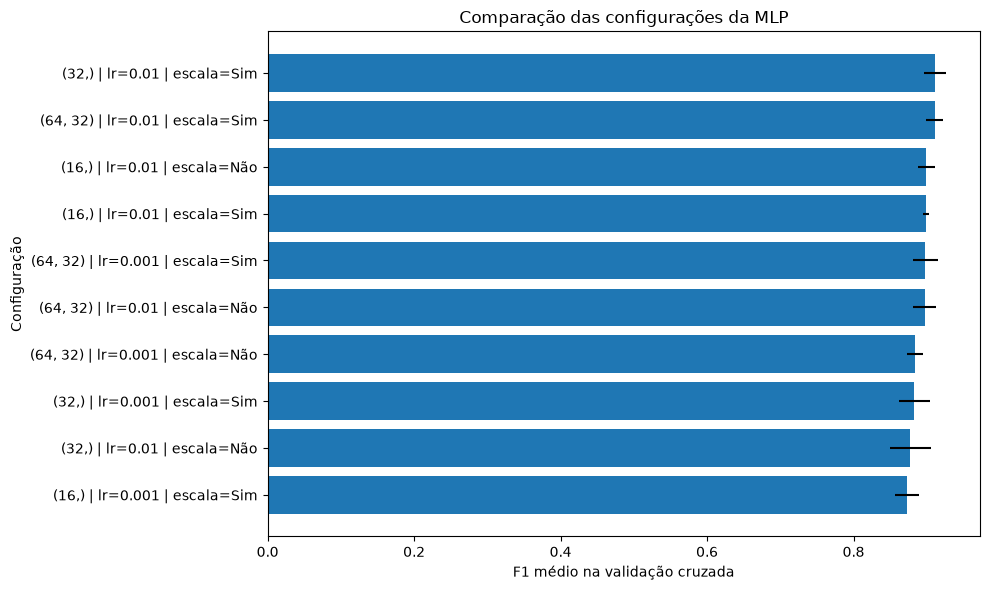

In [23]:
melhores = comparacao.head(10).copy()

melhores["Configuração"] = (
    melhores["Camadas ocultas"]
    + " | lr="
    + melhores["Taxa de aprendizagem"].astype(str)
    + " | escala="
    + melhores["Padronização"]
)

melhores = melhores.sort_values("F1 validação")

plt.figure(figsize=(10, 6))
plt.barh(
    melhores["Configuração"],
    melhores["F1 validação"],
    xerr=melhores["Desvio F1 validação"]
)
plt.xlabel("F1 médio na validação cruzada")
plt.ylabel("Configuração")
plt.title("Comparação das configurações da MLP")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

modelo_final = busca.best_estimator_

y_pred = modelo_final.predict(X_teste)
y_prob = modelo_final.predict_proba(X_teste)[:, 1]

metricas = pd.Series({
    "Acurácia": accuracy_score(y_teste, y_pred),
    "Precisão": precision_score(
        y_teste, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_teste, y_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_teste, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_teste, y_prob)
})

display(metricas.to_frame("Resultado no teste").round(4))

print(classification_report(
    y_teste,
    y_pred,
    target_names=["Não spam", "Spam"],
    zero_division=0
))

,Resultado no teste
Acurácia,0.9400
Precisão,0.9197
Recall,0.9288
F1-score,0.9242
ROC-AUC,0.9833


              precision    recall  f1-score   support

    Não spam       0.95      0.95      0.95       930
        Spam       0.92      0.93      0.92       604

    accuracy                           0.94      1534
   macro avg       0.94      0.94      0.94      1534
weighted avg       0.94      0.94      0.94      1534



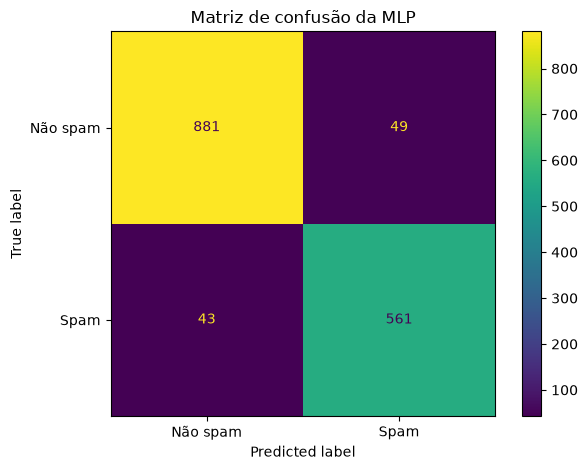

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    y_pred,
    display_labels=["Não spam", "Spam"],
    values_format="d"
)

plt.title("Matriz de confusão da MLP")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)

pred_baseline = baseline.predict(X_teste)

comparacao_final = pd.DataFrame({
    "Modelo": ["Classe mais frequente", "MLP"],
    "Acurácia": [
        accuracy_score(y_teste, pred_baseline),
        accuracy_score(y_teste, y_pred)
    ],
    "Precisão": [
        precision_score(
            y_teste, pred_baseline, zero_division=0
        ),
        precision_score(
            y_teste, y_pred, zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_teste, pred_baseline, zero_division=0
        ),
        recall_score(
            y_teste, y_pred, zero_division=0
        )
    ],
    "F1-score": [
        f1_score(
            y_teste, pred_baseline, zero_division=0
        ),
        f1_score(
            y_teste, y_pred, zero_division=0
        )
    ]
})

display(comparacao_final.set_index("Modelo").round(4))

,Acurácia,Precisão,Recall,F1-score
Modelo,,,,
Classe mais frequente,0.6063,0.0000,0.0000,0.0000
MLP,0.9400,0.9197,0.9288,0.9242


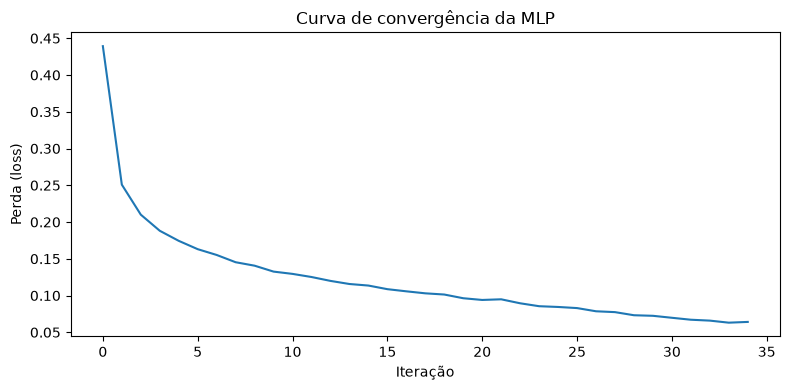

Iterações realizadas: 35
Limite de iterações: 500
Perda final: 0.0641


In [27]:
mlp_final = modelo_final.named_steps["mlp"]

plt.figure(figsize=(8, 4))
plt.plot(mlp_final.loss_curve_)
plt.xlabel("Iteração")
plt.ylabel("Perda (loss)")
plt.title("Curva de convergência da MLP")
plt.tight_layout()
plt.show()

print(f"Iterações realizadas: {mlp_final.n_iter_}")
print(f"Limite de iterações: {mlp_final.max_iter}")
print(f"Perda final: {mlp_final.loss_:.4f}")